# What San Francisco Lets You Build

The city's official zoning districts, grouped by what they allow. Run `fetch_week1.py day3` first.

## 1 · Settings

In [1]:
DAY      = 3
PROMPT   = "Polygons"
SLUG     = "polygons-sf-zoning"
NOTEBOOK = "day03_polygons_sf_zoning.ipynb"
TITLE    = "What San Francisco\nLets You Build"
CREDITS  = "Zoning Map, Zoning Districts: DataSF, City and County of San Francisco. Base zoning only; state law and special programs can allow more."

## 2 · Load

In [2]:
import geopandas as gpd, matplotlib.pyplot as plt, numpy as np, pandas as pd
from mapkit import poster, publish
from mapkit.paths import PROCESSED

zoning = gpd.read_file(PROCESSED / "sf_zoning.geojson")

c:\Users\gauta\.conda\envs\geospatial\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


## 3 · Analysis, every number on the map comes from here

In [3]:
GROUPS = {"One-family houses": "#1d4e9e", "Two- and three-family houses": "#0f9b8e", "Apartments": "#f4b41a",
          "Shops, offices and mixed use": "#e8402c", "Industry": "#a3238e", "Parks and public land": "#e6e1cf"}

def group(row):
    code, kind = str(row.zoning_sim), str(row["gen"])
    if kind == "Public":
        return "Parks and public land"
    if kind == "Industrial":
        return "Industry"
    if code.startswith("RH-1"):
        return "One-family houses"
    if code in ("RH-2", "RH-3"):
        return "Two- and three-family houses"
    if kind == "Residential" or code.startswith(("RTO", "RM")):
        return "Apartments"
    return "Shops, offices and mixed use"

zoning["group"] = zoning.apply(group, axis=1)
zoning["km2"] = zoning.to_crs(32610).area / 1e6
totals = zoning.groupby("group").km2.sum().reindex(GROUPS)
buildable = totals.drop("Parks and public land").sum()
one_or_two = zoning[zoning.zoning_sim.astype(str).str.startswith("RH-1") | (zoning.zoning_sim == "RH-2")].km2.sum()
share = one_or_two / buildable * 100
print((totals / totals.sum() * 100).round(1).to_string())
print(f"Non-public land          {buildable:.1f} km2")
print(f"One or two family zones  {one_or_two:.1f} km2, {share:.1f}% of non-public land")
print(f"Apartments               {totals['Apartments'] / buildable * 100:.1f}% of non-public land")

group
One-family houses               24.1
Two- and three-family houses    12.5
Apartments                      10.4
Shops, offices and mixed use    14.3
Industry                         6.1
Parks and public land           32.5
Non-public land          61.8 km2
One or two family zones  31.1 km2, 50.3% of non-public land
Apartments               15.5% of non-public land


## 4 · Map

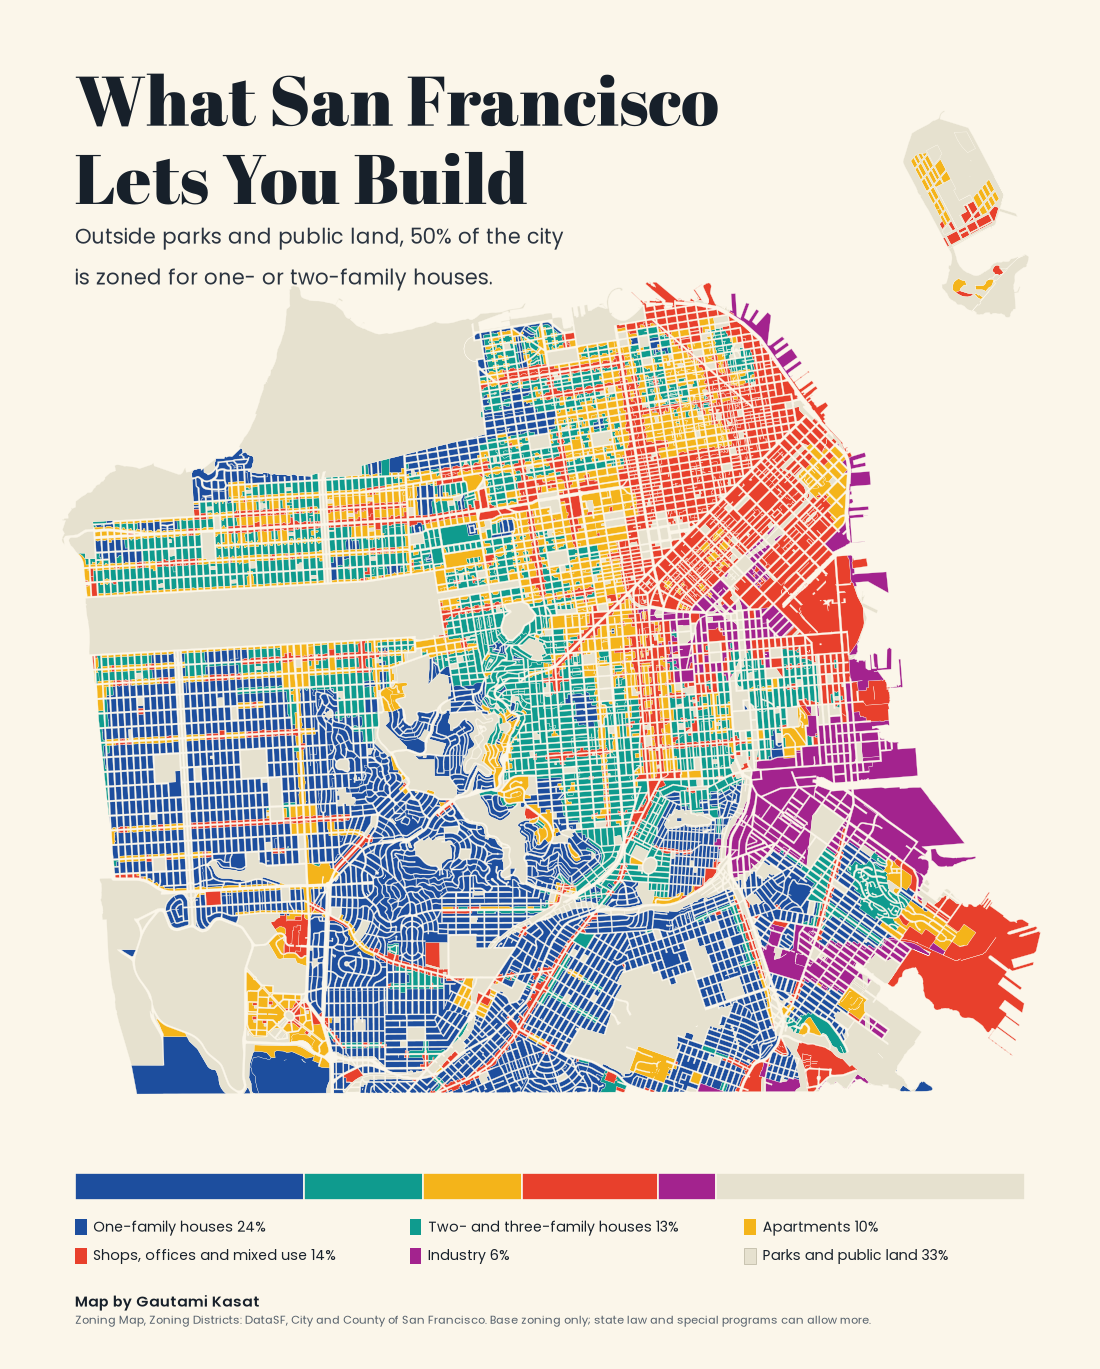

In [4]:
PAPER, INK = "#fbf6ea", "#17202a"
fig, ax = poster.page(PAPER)
m = zoning.to_crs(3857)
for name, color in GROUPS.items():
    m[m.group == name].plot(ax=ax, color=color, edgecolor=PAPER, lw=0.22, zorder=2)
ax.set_axis_off()
fx0, fy0, fx1, fy1 = poster.fit_frame(ax, -122.523, 37.704, -122.349, 37.8125)
h = fy1 - fy0
ax.set_ylim(fy0 + h * 0.012, fy1 + h * 0.012)

fig.text(0.06, 0.968, "What San Francisco", color=INK, fontproperties=poster.font(poster.ABRIL, 50), va="top")
fig.text(0.06, 0.91, "Lets You Build", color=INK, fontproperties=poster.font(poster.ABRIL, 50), va="top")
fig.text(0.06, 0.845, f"Outside parks and public land, {share:.0f}% of the city\nis zoned for one- or two-family houses.", color="#2b3440",
         fontproperties=poster.font(poster.POPPINS, 15), va="top", linespacing=1.4)

# a proportional bar as the legend, so the color key also shows the shares
bar = fig.add_axes([0.06, 0.118, 0.88, 0.02]); bar.set_axis_off()
left = 0
for name, color in GROUPS.items():
    bar.barh(0, totals[name], left=left, color=color, edgecolor=PAPER, lw=1.2, height=1)
    left += totals[name]
bar.set_xlim(0, left); bar.set_ylim(-0.5, 0.5)
names = list(GROUPS)
for i, name in enumerate(names):
    col, row = i % 3, i // 3
    x, y = 0.06 + col * 0.31, 0.098 - row * 0.021
    fig.patches.append(plt.Rectangle((x, y - 0.0065), 0.011, 0.012, transform=fig.transFigure, color=GROUPS[name], ec="#b9b39f" if i == 5 else "none", lw=0.5))
    fig.text(x + 0.017, y, f"{name} {totals[name] / totals.sum() * 100:.0f}%", color=INK, fontproperties=poster.font(poster.POPPINS, 10.2), va="center")
poster.credit(fig, CREDITS, path=poster.POPPINS, name_path=poster.POPPINS_BOLD, color="#55606b", name_color=INK, size=8.2)

## 5 · Export

In [5]:
publish.save(fig, day=DAY, slug=SLUG, prompt=PROMPT, title=TITLE.replace("\n", " "),
             subtitle=f"{share:.0f}% of non-public land is zoned for one- or two-family houses", series="city", tool="Python",
             notebook=NOTEBOOK, credits=CREDITS)

map        output/day03_polygons-sf-zoning.png
thumbnail  png_thumbnail/day03_polygons-sf-zoning.png
caption    captions/day03_polygons-sf-zoning.md
live link  https://gautamik01.github.io/30-day-map-challenge-2026/output/day03_polygons-sf-zoning.png  (after you push)
